# 3.7 Subject framing example

Demonstrate box geometry with known subjects. These are measurements, not brand scores.
The manual region stands in for the detector/selector output. No model download is required.
All coordinates refer to the standardized RGB/sRGB image. 

In [1]:
import json

from IPython.display import display
from PIL import Image, ImageDraw

from brandlens.cv.cv_input import CVInput
from brandlens.cv.subject.region import SubjectRegion
from brandlens.cv.subject_framing_criterion import SubjectFramingCriterion

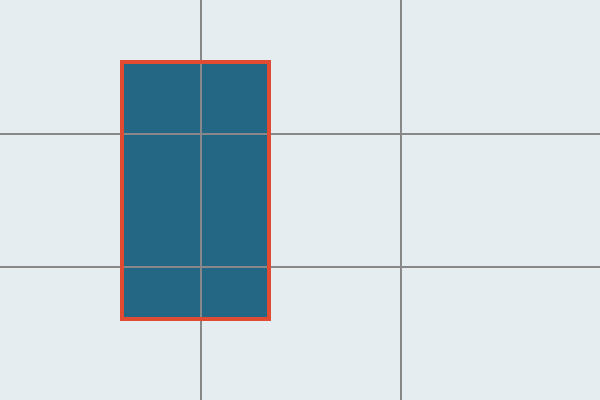

In [2]:
image = Image.new("RGB", (600, 400), "#e5edf1")
box = SubjectRegion(.20, .15, .45, .80, reliable=True,
                    source="manual_demo", source_version="1", label="illustrated subject")
draw = ImageDraw.Draw(image)
draw.rectangle((120, 60, 270, 320), fill="#246785")
preview = image.copy()
draw = ImageDraw.Draw(preview)
for x in (200, 400):
    draw.line((x, 0, x, 400), fill="#888888", width=2)
for y in (400/3, 800/3):
    draw.line((0, y, 600, y), fill="#888888", width=2)
draw.rectangle((120, 60, 270, 320), outline="#e14b31", width=4)
display(preview)


In [3]:
criterion = SubjectFramingCriterion({"edge_margin_fraction": 0.02})
result = criterion.analyze(CVInput(image, subject_region=box))
print(json.dumps(result, indent=2))

{
  "schema_version": "1.0.0",
  "criterion_id": "framing_subject_position",
  "status": "available",
  "measurements": {
    "subject_center_x": 0.325,
    "subject_center_y": 0.47500000000000003,
    "subject_box_area_fraction": 0.1625,
    "center_distance": 0.14626766822928017,
    "nearest_thirds_distance": 0.07888783555333866,
    "left_margin": 0.2,
    "right_margin": 0.55,
    "top_margin": 0.15,
    "bottom_margin": 0.19999999999999996,
    "near_edge": false
  },
  "method": {
    "id": "normalized_subject_box_geometry",
    "version": "1",
    "parameters": {
      "edge_margin_fraction": 0.02
    }
  },
  "units": {
    "subject_center_x": "fraction",
    "subject_center_y": "fraction",
    "subject_box_area_fraction": "fraction",
    "center_distance": "image_diagonal_fraction",
    "nearest_thirds_distance": "image_diagonal_fraction",
    "left_margin": "fraction",
    "right_margin": "fraction",
    "top_margin": "fraction",
    "bottom_margin": "fraction",
    "near_ed

The center is the box midpoint, not an eye/face landmark. Coverage is bounding-box area.
Distances use pixel geometry divided by image diagonal; margins use width or height.
A smaller thirds distance does not automatically mean better composition.
`near_edge` describes proximity, not confirmed cropping.

In [4]:
placements = {
    "centered": (.35, .30, .65, .70),
    "near upper-left thirds": (.23, .23, .43, .43),
    "near left edge": (.01, .20, .30, .80),
}
for name, coordinates in placements.items():
    subject = SubjectRegion(*coordinates, reliable=True, source="manual_demo")
    values = criterion.analyze(CVInput(image, subject))["measurements"]
    print(name, {key: round(values[key], 4) for key in
                 ("center_distance", "nearest_thirds_distance", "subject_box_area_fraction")},
          "near_edge:", values["near_edge"])

centered {'center_distance': 0.0, 'nearest_thirds_distance': 0.1667, 'subject_box_area_fraction': 0.12} near_edge: False
near upper-left thirds {'center_distance': 0.17, 'nearest_thirds_distance': 0.0033, 'subject_box_area_fraction': 0.04} near_edge: False
near left edge {'center_distance': 0.2871, 'nearest_thirds_distance': 0.1748, 'subject_box_area_fraction': 0.174} near_edge: True


## No selected subject
Unsupported/ambiguous images stay visible for review rather than receiving a zero score.

In [5]:
missing = CVInput(image, subject_unavailable_reason="Multiple subjects require review.")
print(json.dumps(criterion.analyze(missing), indent=2))

{
  "schema_version": "1.0.0",
  "criterion_id": "framing_subject_position",
  "status": "unavailable_needs_review",
  "measurements": {},
  "method": {
    "id": "normalized_subject_box_geometry",
    "version": "1",
    "parameters": {
      "edge_margin_fraction": 0.02
    }
  },
  "units": {},
  "reasons": [
    "Multiple subjects require review."
  ]
}
